<a href="https://colab.research.google.com/github/mlewis26/eeg-alpha-eyes-open-closed/blob/main/eeg-alpha-eyes-open-closed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip install mne

import mne
from mne.datasets import eegbci
import time
from urllib.error import HTTPError

mne.set_log_level("WARNING")  # keeps the output quiet

data = {}

for subj in range(1, 11):
    # Try to load the data with up to 3 retries in case of temporary server errors
    for attempt in range(3):
        try:
            files = eegbci.load_data(subj, runs=[1, 2])  # run 1 = eyes open, run 2 = eyes closed
            break
        except Exception as e:
            if attempt < 2:
                print(f"Connection attempt {attempt + 1} failed for subject {subj}. Retrying in 5 seconds...")
                time.sleep(5)
            else:
                raise e

    raws = []
    for f in files:
        raw = mne.io.read_raw_edf(f, preload=True)
        eegbci.standardize(raw)   # fixes the channel names
        raw.filter(1., 40.)       # keep 1-40 Hz
        raws.append(raw)
    data[subj] = {"open": raws[0], "closed": raws[1]}
    print("Loaded subject", subj)

Loaded subject 1
Loaded subject 2
Loaded subject 3
Loaded subject 4
Loaded subject 5
Loaded subject 6
Loaded subject 7
Loaded subject 8
Loaded subject 9
Loaded subject 10


In [ ]:
subj = 10
files = eegbci.load_data(subj, runs=[1, 2])
raws = []
for f in files:
    raw = mne.io.read_raw_edf(f, preload=True)
    eegbci.standardize(raw)
    raw.filter(1., 40.)
    raws.append(raw)
data[subj] = {"open": raws[0], "closed": raws[1]}
print("Loaded subject", subj, "| subjects loaded:", len(data))


In [ ]:
import numpy as np

occipital = ["O1", "Oz", "O2"]   # back-of-head channels, where alpha is strongest
alpha_open, alpha_closed = [], []

for subj in range(1, 11):
    for cond, store in [("open", alpha_open), ("closed", alpha_closed)]:
        raw = data[subj][cond]
        psd = raw.compute_psd(fmin=8, fmax=12, picks=occipital)
        power, freqs = psd.get_data(return_freqs=True)
        store.append(power.mean() * 1e12)   # convert to µV²/Hz

alpha_open = np.array(alpha_open)
alpha_closed = np.array(alpha_closed)

for i in range(10):
    print(f"Subject {i+1}: open = {alpha_open[i]:.2f}, closed = {alpha_closed[i]:.2f}")

Subject 1: open = 45.24, closed = 717.60
Subject 2: open = 21.46, closed = 246.78
Subject 3: open = 36.99, closed = 722.54
Subject 4: open = 3.68, closed = 106.14
Subject 5: open = 5.17, closed = 8.08
Subject 6: open = 3.45, closed = 3.66
Subject 7: open = 77.00, closed = 470.04
Subject 8: open = 8.04, closed = 52.63
Subject 9: open = 21.35, closed = 69.35
Subject 10: open = 36.59, closed = 510.88


In [ ]:
from scipy import stats

t, p = stats.ttest_rel(alpha_closed, alpha_open)   # paired t-test
print(f"Mean alpha, eyes open:   {alpha_open.mean():.2f} µV²/Hz")
print(f"Mean alpha, eyes closed: {alpha_closed.mean():.2f} µV²/Hz")
print(f"Paired t-test: t = {t:.2f}, p = {p:.4f}")

Mean alpha, eyes open:   25.90 µV²/Hz
Mean alpha, eyes closed: 290.77 µV²/Hz
Paired t-test: t = 3.08, p = 0.0131


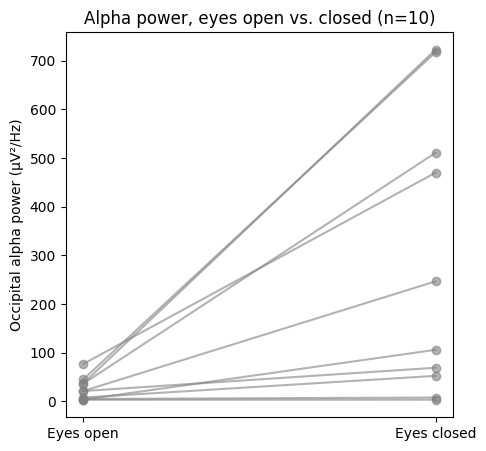

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
for o, c in zip(alpha_open, alpha_closed):
    ax.plot(["Eyes open", "Eyes closed"], [o, c], "-o", color="gray", alpha=0.6)
ax.set_ylabel("Occipital alpha power (µV²/Hz)")
ax.set_title("Alpha power, eyes open vs. closed (n=10)")
plt.show()

In [ ]:
log_open = np.log10(alpha_open)
log_closed = np.log10(alpha_closed)
t, p = stats.ttest_rel(log_closed, log_open)
print(f"Log-transformed paired t-test: t = {t:.2f}, p = {p:.4f}")

Log-transformed paired t-test: t = 5.62, p = 0.0003
